In [1]:
import os
import numpy as np
import random

from IPython.core.pylabtools import figsize
from PIL import Image, ImageEnhance
import kagglehub

import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten, Dropout
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import VGG16
from sklearn.utils import shuffle

from sklearn.metrics import confusion_matrix, classification_report, auc, roc_curve
import seaborn as sns
from sklearn.preprocessing import label_binarize

import warnings
warnings.filterwarnings("ignore")

/Users/nur/code/ml/projects/brain-tumor/ml/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

Path to dataset files: /Users/nur/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2


# Load Datasets

In [3]:
train_dir = '/Users/nur/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Training'
test_dir = '/Users/nur/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Testing'

In [4]:
train_paths = []
train_labels = []

for label in os.listdir(train_dir):
    for image in os.listdir(os.path.join(train_dir, label)):
        train_paths.append(os.path.join(train_dir, label, image))
        train_labels.append(label)

train_paths, train_labels = shuffle(train_paths, train_labels)

In [5]:
train_paths

['/Users/nur/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Training/meningioma/Tr-me_347.jpg',
 '/Users/nur/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Training/notumor/Tr-no_72.jpg',
 '/Users/nur/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Training/meningioma/Tr-me_608.jpg',
 '/Users/nur/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Training/pituitary/Tr-pi_288.jpg',
 '/Users/nur/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Training/pituitary/Tr-pi_213.jpg',
 '/Users/nur/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Training/pituitary/Tr-pi_1349.jpg',
 '/Users/nur/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Training/meningioma/Tr-me_531.jpg',
 '/Users/nur/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Training/pituitary/Tr-pi_1

In [6]:
train_labels

['meningioma',
 'notumor',
 'meningioma',
 'pituitary',
 'pituitary',
 'pituitary',
 'meningioma',
 'pituitary',
 'glioma',
 'notumor',
 'notumor',
 'meningioma',
 'glioma',
 'glioma',
 'pituitary',
 'notumor',
 'notumor',
 'pituitary',
 'notumor',
 'pituitary',
 'meningioma',
 'pituitary',
 'glioma',
 'meningioma',
 'pituitary',
 'meningioma',
 'glioma',
 'meningioma',
 'notumor',
 'pituitary',
 'meningioma',
 'notumor',
 'glioma',
 'pituitary',
 'glioma',
 'glioma',
 'pituitary',
 'pituitary',
 'notumor',
 'notumor',
 'pituitary',
 'pituitary',
 'pituitary',
 'glioma',
 'meningioma',
 'notumor',
 'notumor',
 'glioma',
 'notumor',
 'pituitary',
 'glioma',
 'notumor',
 'glioma',
 'glioma',
 'meningioma',
 'meningioma',
 'glioma',
 'meningioma',
 'meningioma',
 'glioma',
 'pituitary',
 'notumor',
 'glioma',
 'pituitary',
 'glioma',
 'notumor',
 'glioma',
 'glioma',
 'glioma',
 'pituitary',
 'meningioma',
 'notumor',
 'glioma',
 'notumor',
 'notumor',
 'meningioma',
 'meningioma',
 'glio

In [7]:
test_paths = []
test_labels = []

for label in os.listdir(test_dir):
    for image in os.listdir(os.path.join(test_dir, label)):
        test_paths.append(os.path.join(test_dir, label, image))
        test_labels.append(label)

# Data Visualization

In [8]:
random_indices = random.sample(range(len(train_paths)), 9)

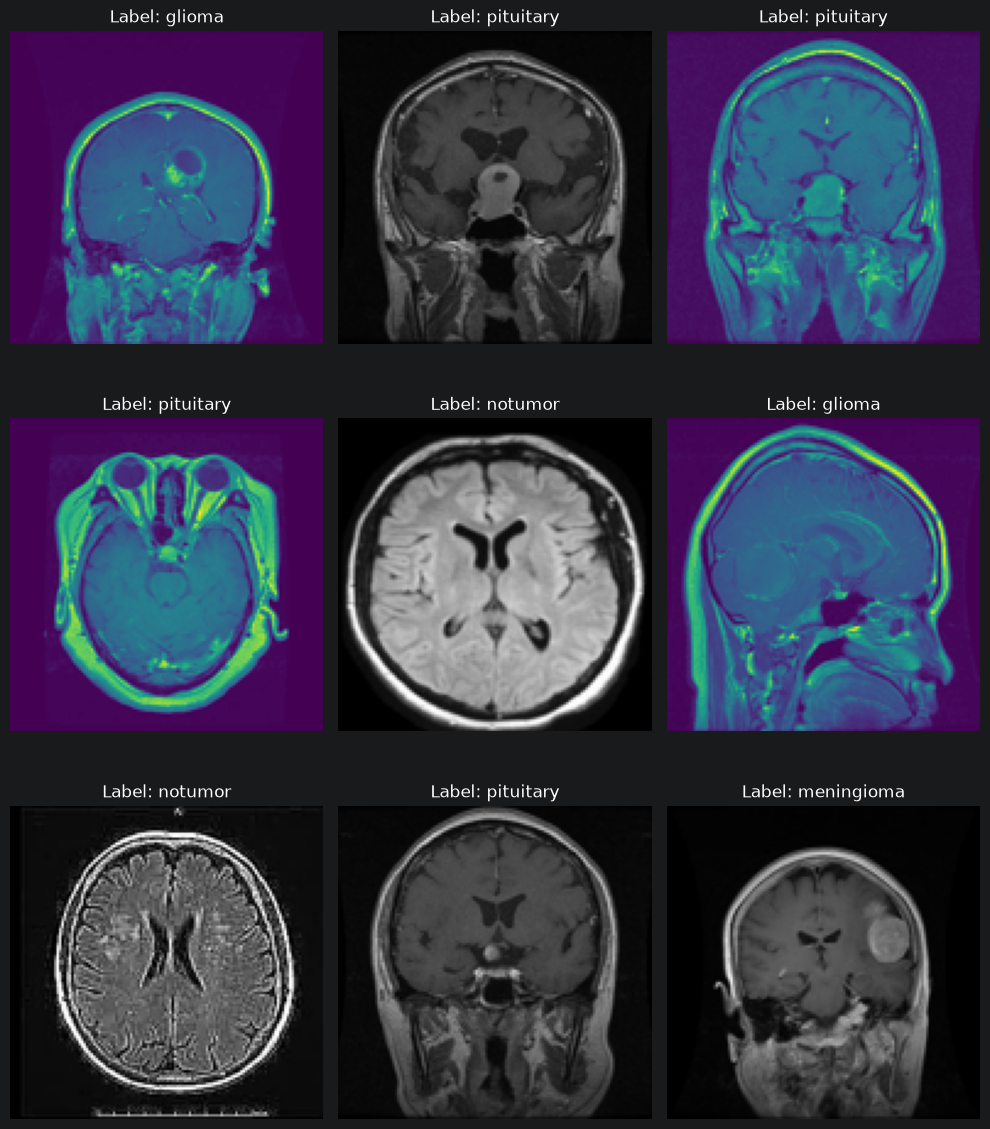

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(10, 12))
axes = axes.ravel()

for i, index in enumerate(random_indices):
    img_path = train_paths[index]
    img = Image.open(img_path)
    img = img.resize((128, 128))
    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(f"Label: {train_labels[index]}")

plt.tight_layout()
plt.show()


# Image Preprocessing (Helper Functions)

In [10]:
# Image Augmentation Function
def augment_image(image):
    image = Image.fromarray(np.uint8(image))
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.5, 1.2))
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.5, 1.2))
    image = np.array(image)/255
    return image

# Load Images and Apply Augmentation
def open_image(paths):
    images = []
    for path in paths:
        img = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        img = augment_image(img)
        images.append(img)
    return np.array(images)


# Encode class names into integer labels
def encode_label(labels):
    unique_labels = sorted(os.listdir(train_dir))
    return np.array(
        [unique_labels.index(label) for label in labels],
        dtype=np.int32
    )


# Data Generator for Batching
def data_generator(paths, labels, batch_size=20):
    indices = np.arange(len(paths))

    while True:
        np.random.shuffle(indices)

        for i in range(0, len(paths), batch_size):
            batch_indices = indices[i:i + batch_size]

            batch_paths = [paths[j] for j in batch_indices]
            batch_labels = [labels[j] for j in batch_indices]

            batch_images = open_image(batch_paths)
            batch_labels = encode_label(batch_labels)

            yield batch_images, batch_labels

# Model

In [11]:
IMAGE_SIZE = 256
base_model = VGG16(
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    include_top=False,
    weights='imagenet',
)

In [12]:
# Freeze all layers
for layer in base_model.layers:
    layer.trainable = False

# Set only the last few layers
base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True

In [13]:
model = Sequential()
model.add(Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)))
model.add(base_model)
model.add(Flatten())
model.add(Dropout(0.3))
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(len(os.listdir(train_dir)), activation='softmax'))

In [14]:
model.compile(optimizer=Adam(learning_rate=0.0001), loss='sparse_categorical_crossentropy', metrics=['sparse_categorical_accuracy'])

In [15]:

import math

batch_size = 20
epochs = 12

steps = math.ceil(len(train_paths) / batch_size)

history = model.fit(
    data_generator(
        train_paths,
        train_labels,
        batch_size=batch_size
    ),
    steps_per_epoch=steps,
    epochs=epochs
)

Epoch 1/12
128/280 ━━━━━━━━━━━━━━━━━━━━ 20:20 8s/step - loss: 0.6619 - sparse_categorical_accuracy: 0.7395

W0000 00:00:1791711700.069186 11170820 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791711317174930000 in buffer 'PrefetchDataset/_4' sat unconsumed for 382.692 seconds!


136/280 ━━━━━━━━━━━━━━━━━━━━ 20:20 8s/step - loss: 0.6468 - sparse_categorical_accuracy: 0.7471

W0000 00:00:1791711824.619701 11170820 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791711745268802000 in buffer 'PrefetchDataset/_4' sat unconsumed for 79.2492 seconds!


280/280 ━━━━━━━━━━━━━━━━━━━━ 1829s 7s/step - loss: 0.4970 - sparse_categorical_accuracy: 0.8096
Epoch 2/12
280/280 ━━━━━━━━━━━━━━━━━━━━ 1306s 5s/step - loss: 0.2166 - sparse_categorical_accuracy: 0.9220
Epoch 3/12
280/280 ━━━━━━━━━━━━━━━━━━━━ 1342s 5s/step - loss: 0.1425 - sparse_categorical_accuracy: 0.9471
Epoch 4/12
280/280 ━━━━━━━━━━━━━━━━━━━━ 1312s 5s/step - loss: 0.0870 - sparse_categorical_accuracy: 0.9682
Epoch 5/12
280/280 ━━━━━━━━━━━━━━━━━━━━ 1267s 5s/step - loss: 0.0801 - sparse_categorical_accuracy: 0.9718
Epoch 6/12
162/280 ━━━━━━━━━━━━━━━━━━━━ 11:04 6s/step - loss: 0.0595 - sparse_categorical_accuracy: 0.9781

...

280/280 ━━━━━━━━━━━━━━━━━━━━ 1286s 5s/step - loss: 0.0384 - sparse_categorical_accuracy: 0.9875
Epoch 12/12
 21/280 ━━━━━━━━━━━━━━━━━━━━ 1:45:26 24s/step - loss: 0.0091 - sparse_categorical_accuracy: 1.0000

W0000 00:00:1791731993.639476 11170820 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791731590365365000 in buffer 'PrefetchDataset/_4' sat unconsumed for 403.128 seconds!


 32/280 ━━━━━━━━━━━━━━━━━━━━ 1:20:25 19s/step - loss: 0.0088 - sparse_categorical_accuracy: 0.9984

W0000 00:00:1791732108.335997 11170820 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791732037046859000 in buffer 'PrefetchDataset/_4' sat unconsumed for 71.1909 seconds!


280/280 ━━━━━━━━━━━━━━━━━━━━ 1811s 6s/step - loss: 0.0212 - sparse_categorical_accuracy: 0.9932   


# Model Evaluation

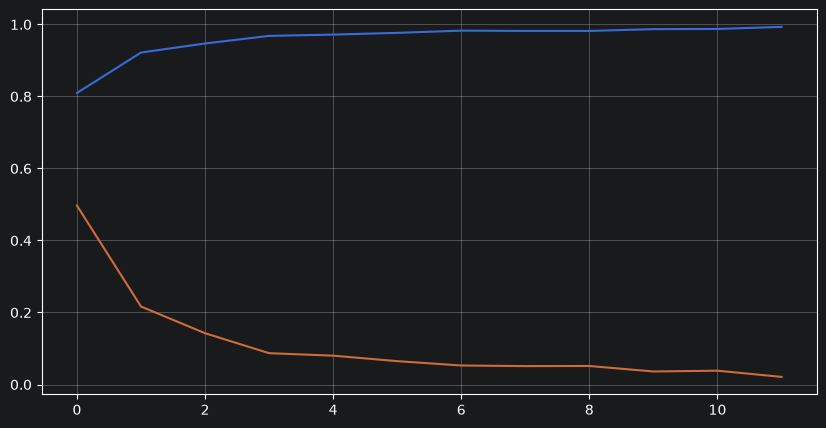

In [16]:
plt.figure(figsize=(10, 5))
plt.grid(True)
plt.plot(history.history['sparse_categorical_accuracy'])
plt.plot(history.history['loss'])

In [17]:
test_images = open_image(test_paths)
test_labels_encoded = encode_label(test_labels)

test_pred = model.predict(test_images)

50/50 ━━━━━━━━━━━━━━━━━━━━ 311s 6s/step


In [18]:
print('='*10, 'Classification Report', '='*10)
print(classification_report(test_labels_encoded, np.argmax(test_pred, axis=1)))

========== Classification Report ==========
              precision    recall  f1-score   support

           0       0.94      0.79      0.86       400
           1       0.86      0.98      0.92       400
           2       0.92      1.00      0.96       400
           3       0.99      0.93      0.96       400

    accuracy                           0.92      1600
   macro avg       0.93      0.92      0.92      1600
weighted avg       0.93      0.92      0.92      1600



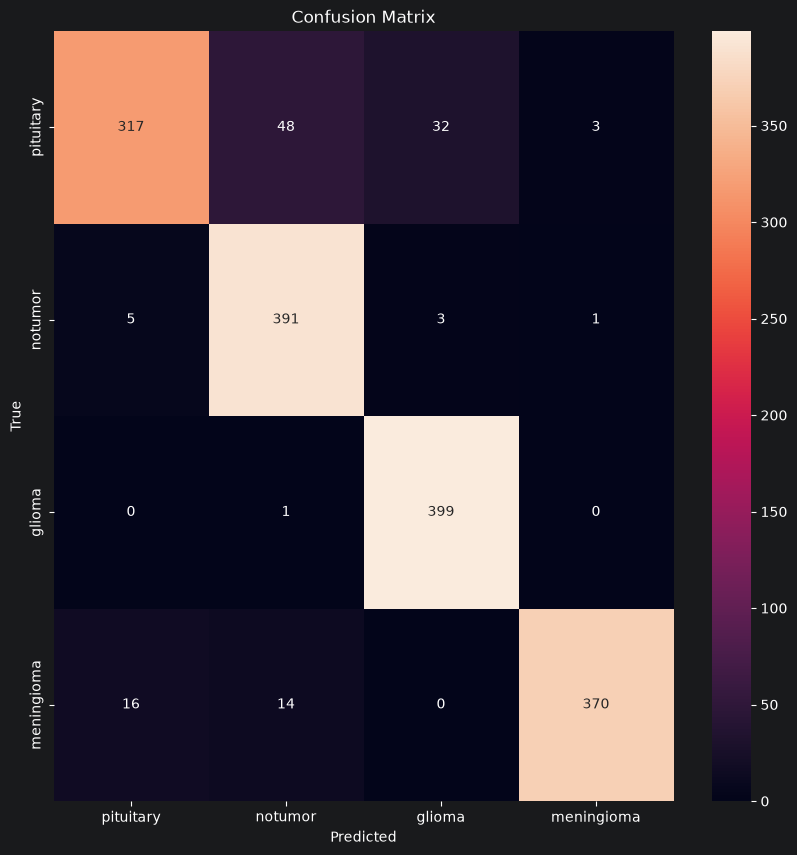

In [19]:
conf_mat = confusion_matrix(test_labels_encoded, np.argmax(test_pred, axis=1))
plt.figure(figsize=(10, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", xticklabels=os.listdir(train_dir), yticklabels=os.listdir(train_dir))
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


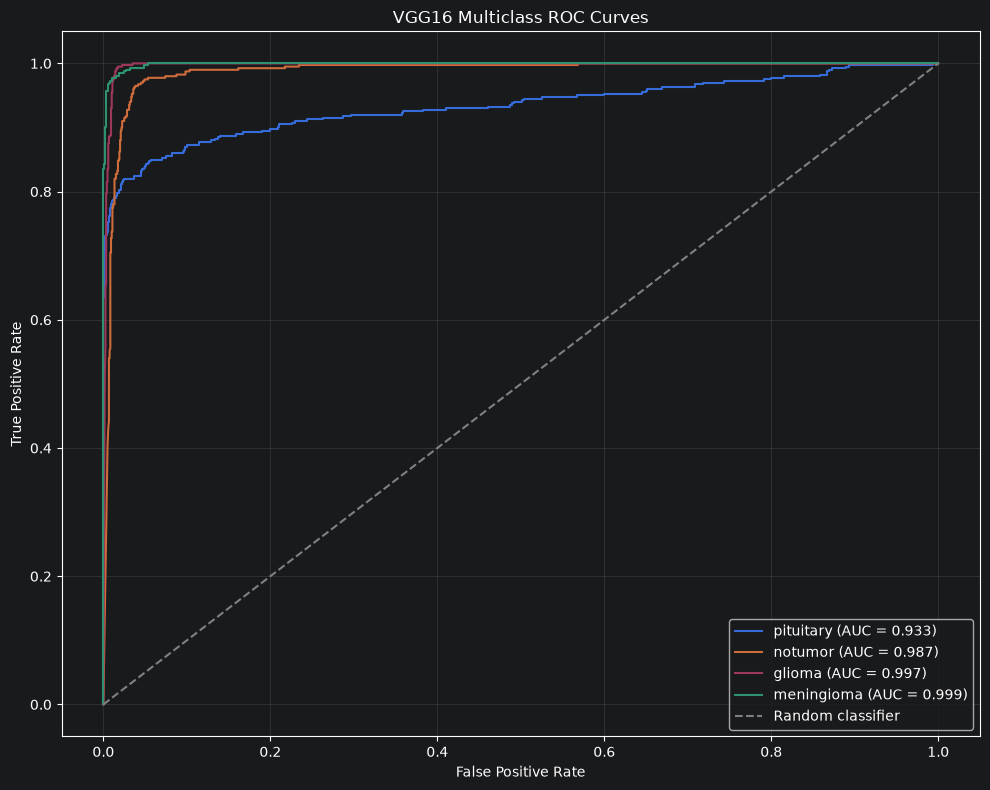

In [20]:
class_names = [
    "pituitary",
    "notumor",
    "glioma",
    "meningioma"
]
num_classes = len(class_names)

test_labels_bin = label_binarize(
    test_labels_encoded,
    classes=np.arange(num_classes)
)

test_predictions_bin = test_pred  # Softmax probabilities

fpr, tpr, roc_auc = {}, {}, {}

for i in range(num_classes):
    fpr[i], tpr[i], thresholds = roc_curve(
        test_labels_bin[:, i],
        test_predictions_bin[:, i]
    )
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(10, 8))

for i in range(num_classes):
    plt.plot(
        fpr[i],
        tpr[i],
        label=f'{class_names[i]} (AUC = {roc_auc[i]:.3f})'
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

plt.title("VGG16 Multiclass ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Save Model

In [21]:
model_dir = '../artifacts'
os.makedirs(model_dir, exist_ok=True)

model.save(os.path.join(model_dir, 'brain-tumor-detection-model.keras'))